In [39]:
import numpy as np
import torch

from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_mll
from botorch.acquisition import qLogNoisyExpectedImprovement
from botorch.optim import optimize_acqf
from gpytorch.mlls import ExactMarginalLogLikelihood

from pathlib import Path
import pandas as pd
import os
import shutil
from spacegraph_codebase.analyze_utils import *


In [40]:
exp_dir = Path("experiments_1028")
script_dir = Path(exp_dir, "scripts")
script_dir.mkdir(parents=True, exist_ok=True)
script_comp_dir = Path(exp_dir, "script_comp")
script_comp_dir.mkdir(parents=True, exist_ok=True)

for f in os.listdir(script_comp_dir):
    source = script_comp_dir / f
    destination = script_dir / f
    shutil.move(source, destination)
make_results_df(exp_dir)


実験数: 110
ログあり: 110
結果を experiments_1028/experiments_results.csv に保存しました。


,data_dir,model_dir,log_dir,num_context_sample,seed,embed_dim,dropout,enc_agg,model_type,num_rbf_anchor_pts,...,test_iter_100neg,stg_total,stg_selected,stg_expected_active,stg_mean_prob,stg_selected_ratio,mu_min,mu_max,mu_mean,mu_nonpositive
0,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,0,64,0.5,mean,global,0,...,2499.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,1,64,0.5,mean,global,0,...,2499.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,2,64,0.5,mean,global,0,...,2499.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,3,64,0.5,mean,global,0,...,2499.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,4,64,0.5,mean,global,0,...,2499.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,0,64,0.5,mean,global,0,...,2499.0,6341.0,5160.0,4422.62,0.6975,0.813752,-1.1046,1.0589,0.2614,1181.0
106,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,1,64,0.5,mean,global,0,...,2499.0,6341.0,5146.0,4416.21,0.6965,0.811544,-1.1047,1.0764,0.2589,1195.0
107,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,2,64,0.5,mean,global,0,...,2499.0,6341.0,5148.0,4423.54,0.6976,0.811859,-1.1043,1.0926,0.2615,1193.0
108,./data_collection/Place2Vec_center/,./experiments_1028/results,./experiments_1028/results,10,3,64,0.5,mean,global,0,...,2499.0,6341.0,5157.0,4422.28,0.6974,0.813279,-1.1044,1.0925,0.2603,1184.0


In [49]:
df_1028 = pd.read_csv("experiments_1028/experiments_results.csv")
df_1027 = pd.read_csv("experiments_1027/experiments_results.csv")

df = pd.concat([df_1027, df_1028], ignore_index=True)
df = df[df["wl_func"] == "db4"].copy()

# STGなしの場合、lambdaを0に統一
df.loc[df["use_stg"] == False, "stg_lambda"] = 0.0

# 条件ごとに集計
summary = (
    df[df["stg_sigma"] == 0.5].groupby(["use_stg", "stg_lambda", "min_scale"])
    ["valid_mrr_100neg"]
    .agg(
        mean="mean",
        std="std",
        var="var",
        count="count"
    )
    .reset_index()
    .sort_values(["min_scale", "use_stg", "stg_lambda"])
)

# 平均値の推定分散（BoTorch用）
summary["mean_var"] = summary["var"] / summary["count"]

display(summary)

bo_data = summary[
    (summary["use_stg"] == True) &
    (summary["count"] >= 2)
].dropna(subset=["mean", "mean_var"]).copy()

,use_stg,stg_lambda,min_scale,mean,std,var,count,mean_var
13,True,0.130,200,0.120100,0.003514,1.234523e-05,5,2.469047e-06
3,True,0.010,215,0.122710,0.002461,6.054336e-06,5,1.210867e-06
0,False,0.000,250,0.123624,0.002694,7.258654e-06,5,1.451731e-06
20,True,1.000,250,0.124156,0.004303,1.851502e-05,5,3.703004e-06
16,True,0.225,384,0.128328,0.003171,1.005738e-05,5,2.011476e-06
7,True,0.011,397,0.128435,0.000996,9.911793e-07,5,1.982359e-07
18,True,0.290,412,0.124401,0.002322,5.390403e-06,5,1.078081e-06
11,True,0.053,443,0.129015,0.002416,5.837680e-06,5,1.167536e-06
15,True,0.180,458,0.129251,0.002620,6.862468e-06,5,1.372494e-06
8,True,0.023,475,0.128651,0.003525,1.242646e-05,5,2.485292e-06


In [51]:
df_1028 = pd.read_csv("experiments_1028/experiments_results.csv")
df_1027 = pd.read_csv("experiments_1027/experiments_results.csv")

df = pd.concat([df_1027, df_1028], ignore_index=True)
df = df[df["wl_func"] == "db4"].copy()

# STGなしの場合、lambdaを0に統一
df.loc[df["use_stg"] == False, "stg_lambda"] = 0.0

# 条件ごとに集計
summary2 = (
    df[df["stg_sigma"] == 0.5]
    .groupby(["use_stg", "stg_lambda", "min_scale"])
    .agg(
        mean=("test_mrr_100neg", "mean"),
        std=("test_mrr_100neg", "std"),
        var=("test_mrr_100neg", "var"),
        count=("test_mrr_100neg", "count"),

        # 基底選択
        stg_total=("stg_total", "mean"),
        stg_selected_mean=("stg_selected", "mean"),
        stg_selected_std=("stg_selected", "std"),
        stg_selected_ratio_mean=("stg_selected_ratio", "mean"),
        stg_selected_ratio_std=("stg_selected_ratio", "std"),
        stg_expected_active_mean=("stg_expected_active", "mean"),
    )
    .reset_index()
    .sort_values(["min_scale", "use_stg", "stg_lambda"])
)

# BoTorch用：MRR平均値の推定分散
summary2["mean_var"] = summary2["var"] / summary2["count"]

display(summary2)

# bo_data = summary[
#     (summary["use_stg"] == True) &
#     (summary["count"] >= 2)
# ].dropna(subset=["mean", "mean_var"]).copy()

,use_stg,stg_lambda,min_scale,mean,std,var,count,stg_total,stg_selected_mean,stg_selected_std,stg_selected_ratio_mean,stg_selected_ratio_std,stg_expected_active_mean,mean_var
13,True,0.130,200,0.126304,0.004162,0.000017,5,75138.0,33383.4,81.622913,0.444294,0.001086,29087.120,3.464921e-06
3,True,0.010,215,0.125228,0.002334,0.000005,5,65912.0,49306.8,78.731823,0.748070,0.001194,41887.878,1.089382e-06
0,False,0.000,250,0.129613,0.005229,0.000027,5,NaN,NaN,NaN,NaN,NaN,NaN,5.468997e-06
20,True,1.000,250,0.128381,0.002029,0.000004,5,48021.0,8098.6,89.536585,0.168647,0.001865,9131.522,8.232689e-07
16,True,0.225,384,0.134033,0.002289,0.000005,5,21125.0,9751.4,20.044949,0.461605,0.000949,8648.774,1.047492e-06
7,True,0.011,397,0.131274,0.003223,0.000010,5,19506.0,16778.4,7.700649,0.860166,0.000395,14314.348,2.077826e-06
18,True,0.290,412,0.129846,0.004492,0.000020,5,18121.0,7539.8,32.135650,0.416081,0.001773,6880.568,4.035880e-06
11,True,0.053,443,0.132212,0.003695,0.000014,5,15704.0,11551.8,24.376218,0.735596,0.001552,9772.468,2.730286e-06
15,True,0.180,458,0.134951,0.004716,0.000022,5,14589.0,7760.2,25.153529,0.531921,0.001724,6792.384,4.448462e-06
8,True,0.023,475,0.136673,0.003090,0.000010,5,13843.0,11306.4,15.757538,0.816759,0.001138,9635.264,1.909992e-06


In [47]:


torch.set_default_dtype(torch.double)

# -------------------------
# 2. 入力を対数変換
# -------------------------
train_X = torch.tensor(
    np.log10(bo_data[["min_scale", "stg_lambda"]].values),
    dtype=torch.double
)

train_Y = torch.tensor(
    bo_data[["mean"]].values,
    dtype=torch.double
)

train_Yvar = torch.tensor(
    bo_data[["mean_var"]].values,
    dtype=torch.double
)

# -------------------------
# 3. 入力の正規化
# -------------------------
lower = torch.tensor([np.log10(200), np.log10(0.01)])
upper = torch.tensor([np.log10(2000), np.log10(1.0)])

train_X_norm = (train_X - lower) / (upper - lower)

# -------------------------
# 4. ガウス過程を学習
# -------------------------
model = SingleTaskGP(
    train_X=train_X_norm,
    train_Y=train_Y,
    train_Yvar=train_Yvar
)

mll = ExactMarginalLogLikelihood(
    model.likelihood, model
)

fit_gpytorch_mll(mll)
model.eval()

# -------------------------
# 5. 獲得関数を構築
# -------------------------
acq_func = qLogNoisyExpectedImprovement(
    model=model,
    X_baseline=train_X_norm
)

# -------------------------
# 6. 次の実験点を選択
# -------------------------
bounds = torch.stack([
    torch.zeros(2),
    torch.ones(2)
])

candidate, acq_value = optimize_acqf(
    acq_function=acq_func,
    bounds=bounds,
    q=1,
    num_restarts=10,
    raw_samples=256
)

# -------------------------
# 7. 元のパラメータに変換
# -------------------------
candidate_log = (
    candidate.detach().cpu() * (upper - lower) + lower
)

next_min_scale = 10 ** candidate_log[0, 0].item()
next_stg_lambda = 10 ** candidate_log[0, 1].item()

print("Next min_scale:", next_min_scale)
print("Next stg_lambda:", next_stg_lambda)


Next min_scale: 629.0118602384798
Next stg_lambda: 0.010300089013375589


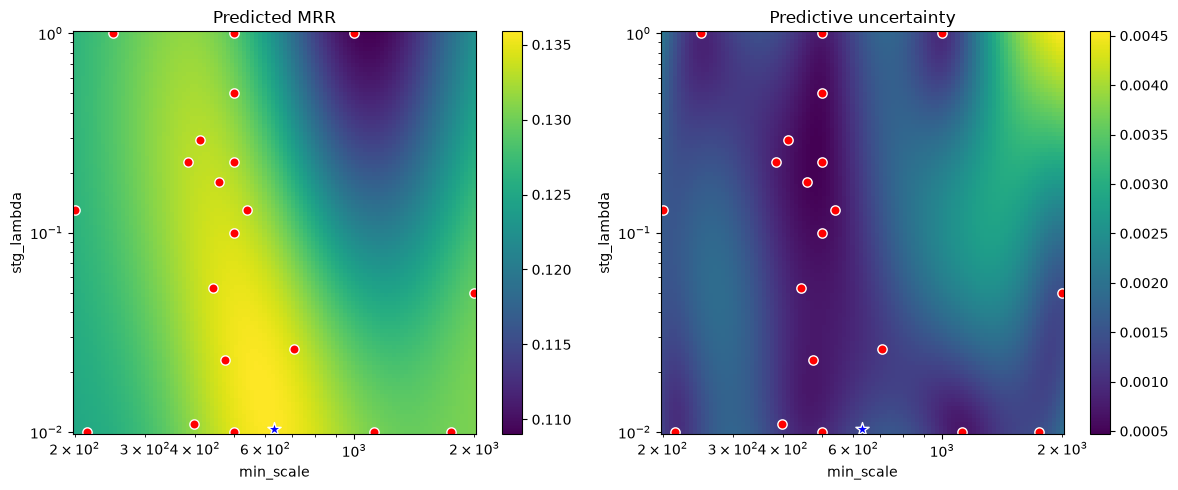

In [48]:

import matplotlib.pyplot as plt

# 対数空間に格子を作成
s_grid = np.linspace(np.log10(200), np.log10(2000), 100)
l_grid = np.linspace(np.log10(0.01), np.log10(1.0), 100)

S, L = np.meshgrid(s_grid, l_grid)

X_grid = torch.tensor(
    np.column_stack([S.ravel(), L.ravel()]),
    dtype=torch.double
)
X_grid_norm = (X_grid - lower) / (upper - lower)

# GPによる予測
with torch.no_grad():
    posterior = model.posterior(X_grid_norm)
    mean = posterior.mean.cpu().numpy().reshape(S.shape)
    std = posterior.variance.sqrt().cpu().numpy().reshape(S.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, Z, title in zip(
    axes,
    [mean, std],
    ["Predicted MRR", "Predictive uncertainty"]
):
    im = ax.pcolormesh(
        10**S, 10**L, Z,
        shading="auto",
        cmap="viridis"
    )

    ax.scatter(
        10**train_X[:, 0], 10**train_X[:, 1],
        c="red", edgecolors="white", s=45
    )

    ax.scatter(
        next_min_scale, next_stg_lambda,
        c="blue", edgecolors="white", s=100, marker="*"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("min_scale")
    ax.set_ylabel("stg_lambda")
    ax.set_title(title)

    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()
